# 2.1 Estimate Array Covariance from Time Series

In this example, we show how to use the ``utils.dsp`` module to process time series into a sample-covariance matrix. We use infrasound from a Hukkakero explosion event recorded by IMS station IS37 as an example.

In [ ]:
#__ Import: Numerical __
import numpy as np

#__ Import: Topophone2 __
import topophone2.utils.dsp as dsp
from topophone2.utils.read import convert_to_txt

#__ Import: Plotting __
import matplotlib.pyplot as plt

Hello from topophone2!


In [ ]:
#__ Set up: Plotting __
theme = ['#DC4424', '#74A466', '#24448C', '#F8BC5C']
small, large = 8, 10
plt.rcParams["font.sans-serif"] = ['Arial']

#__ Disable: Warnings __
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

### 2.1.1 Read data

First, we read in the time series.

In [2]:
#__ Read data __
data = np.load('../data/eg2/IS37_hukkakero_2016-08-19.npz')
u_t = data['u_t']  # Waveform data     [Pa] (receiver, time)
t   = data['t']    # Lapse time vector [s]  (time,)
x   = data['x']    # Receiver location [m]  (receiver, direction)

Second, we split the time series into signal and noise windows. The latter will help constrain the noise parameters during the inversion.

In [3]:
#__ Select signal and noise windows __
T_w   = 20.0                                   # Window half-width [s]
t_w_s = 1360                                   # Signal-window central time [s]
t_w_n = [750, 800, 850, 900, 950, 1000, 1050]  # Noise-window central times [s]

#__ Masks __
win_s = (np.abs(t - t_w_s) < T_w)  # Signal window mask (time,)
win_n = [
    (np.abs(t - t_w_ni) < T_w)     # Noise window mask (time,)
    for t_w_ni in t_w_n
]

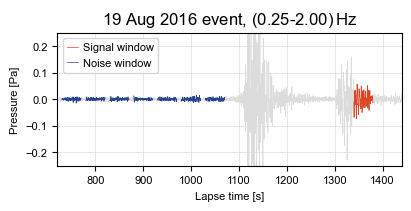

In [ ]:
#__ Create figure and axes __
fig, ax = plt.subplots(figsize=(4,2), facecolor='white', layout='constrained')

#__ Labels __
ax.set_title(r"19 Aug 2016 event, (0.25-2.00)$\,$Hz")
ax.set_xlabel("Lapse time [s]", fontsize=small)
ax.set_ylabel("Pressure [Pa]", fontsize=small)

#__ Ticks __
ax.set_xlim(t[0], t[-1])
ax.set_ylim(-0.25, 0.25)
ax.tick_params(labelsize=small)
ax.grid(color='gainsboro', linewidth=0.5)

#__ Plot waveform __
ax.plot(t, u_t[0], lw=0.5, c='gainsboro', zorder=1)

#__ Plot signal __
ax.plot(t[win_s], u_t[0,win_s], lw=0.5, c=theme[0], zorder=2, label="Signal window")

#__ PLot noise __
for i, win_ni in enumerate(win_n):
    ax.plot(t[win_ni], u_t[0,win_ni], lw=0.5, c=theme[2], zorder=2, label="Noise window" if i == 0 else "_nolegend_")

#__ Legend __
ax.legend(fontsize=small, handlelength=1.0, handletextpad=0.4)

#__ Show figure __
fig.show()

### 2.1.2 Estimate array-covariance within noise windows

When calculating the sample-covariance matrix (estimate to the array-covariance matrix), the expectation over independent realisations must be taken. When the time window must be minimised, taking the mean over Slepian tapers provides a sweet spot between minimimising the time window required and maximising frequency resolution.

In [ ]:
#__ Select frequency bins __
frequency = np.array([0.4, 0.5, 0.6])  # Frequency bins [Hz]

#__ Set Slepian taper bandwidth __
bw = 0.3                               # Full bandwidth [Hz]

The ``utils.dsp.sample_covariance_matrix`` function applies Slepian tapers to the time series, takes the Fourier transform to the frequency domain, takes the inter-sensor cross-spectrum, and then averages over the tapers to give a sample-covariance matrix.

In [6]:
#__ Instantiate storage __
Gamma_obs_noise = np.zeros((len(frequency), len(x), len(x)), dtype='complex')  # Sample-covariance matrix [Pa2.Hz-1] (frequency, receiver, receiver)
N_obs_noise     = 0                                                            # Number of observations

#__ Loop through noise windows __
for win_ni in win_n:

    #__ Window signal __
    u_t_ni, t_ni = u_t[:,win_ni], t[win_ni]
    npts_ni      = np.sum(win_ni)

    #__ Calculate sample-covariance matrix __
    scm, f, N, _ = dsp.sample_covariance_matrix(
        u_t = u_t_ni,      # Time series [Pa] (receiver, time)
        npts = npts_ni,    # Number of points in signal
        dt = t[1] - t[0],  # Sampling interval [s]
        bw = bw            # Taper bandwidth [Hz]
    )

    #__ Pick out frequencies __
    idx = np.argmin(np.abs(f[:, None] - frequency[None, :]), axis=0)

    #__ Append to average across windows __
    Gamma_obs_noise += N * scm[idx]
    N_obs_noise     += N

#__ Average across windows __
Gamma_obs_noise /= N_obs_noise

The ``utils.read.convert_to_txt`` function saves sample-covariance matrices in the _Topophone2_ data format.

In [7]:
#__ Save data __
convert_to_txt(
    frequency   = frequency,
    x           = x,
    Gamma_obs   = Gamma_obs_noise,
    N_obs       = N_obs_noise,
    output_path = "../data/eg2/noise"
)

Data info:
>>> Number of frequency points (N_freq): 3
>>> Number of receiver positions (N_rec): 10
>>> Number of coordinate dimensions (N_dim): 2
>>> Number of observations (N_obs): 70

Flattening Gamma_obs in 'C' order (receiver q varies fastest, then receiver p, then frequency).

Data successfully written to: ../data/hukkakero/noise_topophone2.txt


### Estimate array-covariance within signal window

The moveout phase of the nonstationary signal can cause edge effects for the cross-spectra between widely separated sensors (the signal in the same time window for the two different sensors is different). Therefore, we align the traces first using the function ``utils.dsp.best_beam_DOA`` which maximises the cross-correlation.

In [8]:
#__ Align traces to best-beam direction-of-arrival __
ushift_t, p, shift, npts = dsp.best_beam_DOA(
    u_t = u_t,              # Time series [Pa] (receiver, time)
    t = t,                  # Time vector [s] (time,)
    x = x,                  # Receiver location [s] (receiver, direction)
    p_bounds =[             # Slowness bounds [s.m-1]
        (-2.3e-3,-2.1e-3),  #     Easterly slowness bounds
        (0.8e-3,  1.0e-3)   #     Northerly slowness bounds
    ],
    dp = 0.01e-3,           # Slowness search interval [s.m-1]
    t_w = t_w_s,            # Window central time [s]
    T_w = T_w,              # Window half-width [s]
    alpha_maj = 0.01,       # Pre-FFT taper fraction
    alpha_min = 0.05        # Pre-F-stat taper fraction
)

#__ Print best-beam DOA __
print(f"Best-beam apparent velocity: {1.0 / np.linalg.norm(p):.1f} m.s-1")
print(f"Best-beam backazimuth:       {(np.degrees(np.arctan2(-p[0], -p[1])) % 360):.1f} deg")

Best-beam apparent velocity: 422.6 m.s-1
Best-beam backazimuth:       112.9 deg


Now, the sample-covariance matrix of the time-shifted traces is calculated using the function ``utils.dsp.sample_covariance_matrix``, and the cross-phase is corrected afterwards by specifying the time shifts in the ``correction`` option.

In [9]:
#__ Calculate sample-covariance matrix __
scm, f, N_obs, _ = dsp.sample_covariance_matrix(
    u_t        = ushift_t,     # Shifted time series [Pa] (receiver, time)
    npts       = npts,         # Number of points in signal
    dt         = t[1] - t[0],  # Sampling interval [s]
    bw         = bw,           # Taper bandwidth [Hz]
    correction = - shift       # Correction to shifted traces [s] (receiver,)
)

#__ Pick out frequencies __
idx = np.argmin(np.abs(f[:, None] - frequency[None, :]), axis=0)
Gamma_obs = scm[idx]

#__ Save __
convert_to_txt(
    frequency   = frequency,
    x           = x,
    Gamma_obs   = Gamma_obs,
    N_obs       = N_obs,
    output_path = "../data/eg2/signal"
)

Data info:
>>> Number of frequency points (N_freq): 3
>>> Number of receiver positions (N_rec): 10
>>> Number of coordinate dimensions (N_dim): 2
>>> Number of observations (N_obs): 10

Flattening Gamma_obs in 'C' order (receiver q varies fastest, then receiver p, then frequency).

Data successfully written to: ../data/hukkakero/signal_topophone2.txt
